- Raw dataset: 1,087 rows × 56 columns
- After selecting columns: 1,087 rows × 11 columns
- After removing duplicates (Section 8): 990 rows × 11 columns
- After adding the Status_Group column (Section 13): 990 rows × 12 columns

#  1. IMPORTING LIBRARIES


In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
pd.set_option('display.max_columns',200)

# 2. IMPORTING DATASET

In [109]:
df =pd.read_csv('/kaggle/input/datasets/pushkar975/coaster-db/coaster_db.csv')

# 3. INSPECTING RAW DATASET
Inspect shape, column names, data types, and a sample before changing anything. This helps identify which columns are useful and which fields may require conversion.

In [110]:
df.shape
# df.head(10)

(1087, 56)

In [111]:
df.head(10)

,coaster_name,Length,Speed,Location,Status,Opening date,Type,Manufacturer,Height restriction,Model,Height,Inversions,Lift/launch system,Cost,Trains,Park section,Duration,Capacity,G-force,Designer,Max vertical angle,Drop,Soft opening date,Fast Lane available,Replaced,Track layout,Fastrack available,Soft opening date.1,Closing date,Opened,Replaced by,Website,Flash Pass Available,Must transfer from wheelchair,Theme,Single rider line available,Restraint Style,Flash Pass available,Acceleration,Restraints,Name,year_introduced,latitude,longitude,Type_Main,opening_date_clean,speed1,speed2,speed1_value,speed1_unit,speed_mph,height_value,height_unit,height_ft,Inversions_clean,Gforce_clean
0,Switchback Railway,600 ft (180 m),6 mph (9.7 km/h),Coney Island,Removed,"June 16, 1884",Wood,LaMarcus Adna Thompson,NaN,Lift Packed,50 ft (15 m),NaN,gravity,NaN,NaN,Coney Island Cyclone Site,1:00,1600 riders per hour,2.9,LaMarcus Adna Thompson,30°,43 ft (13 m),NaN,NaN,NaN,Gravity pulled coaster,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1884,40.5740,-73.9780,Wood,1884-06-16,6 mph,9.7 km/h,6.0,mph,6.0,50.0,ft,NaN,0,2.9
1,Flip Flap Railway,NaN,NaN,Sea Lion Park,Removed,1895,Wood,Lina Beecher,NaN,NaN,NaN,1.0,NaN,NaN,a single car. Riders are arranged 1 across in ...,NaN,NaN,NaN,12,Lina Beecher,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1902,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1895,40.5780,-73.9790,Wood,1895-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.0
2,Switchback Railway (Euclid Beach Park),NaN,NaN,"Cleveland, Ohio, United States",Closed,NaN,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1896,41.5800,-81.5700,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,Loop the Loop (Coney Island),NaN,NaN,Other,Removed,1901,Steel,Edwin Prescott,NaN,NaN,NaN,1.0,NaN,NaN,a single car. Riders are arranged 2 across in ...,NaN,NaN,NaN,NaN,Edward A. Green,NaN,NaN,NaN,NaN,Switchback Railway,NaN,NaN,NaN,1910,NaN,Giant Racer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1901,40.5745,-73.9780,Steel,1901-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
4,Loop the Loop (Young's Pier),NaN,NaN,Other,Removed,1901,Steel,Edwin Prescott,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Edward A. Green,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1912,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1901,39.3538,-74.4342,Steel,1901-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
5,Cannon Coaster,NaN,NaN,Coney Island,Removed,1902,Wood,George Francis Meyer,NaN,NaN,40 ft (12 m),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1902,40.5750,-73.9800,Wood,1902-01-01,NaN,NaN,NaN,NaN,NaN,40.0,ft,NaN,0,NaN
6,Leap-The-Dips,"1,452 ft (443 m)",10 mph (16 km/h),Lakemont Park,Operating,1902,Wood – Side friction,Federal Construction Company,NaN,NaN,41 ft (12 m),NaN,NaN,NaN,NaN,NaN,1:00,NaN,NaN,Edward Joy Morris,25°,9 ft (2.7 m),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1902,NaN,NaN,Wood,1902-01-01,10 mph,16 km/h,10.0,mph,10.0,41.0,ft,NaN,0,NaN
7,Figure Eight (Euclid Beach Park),NaN,NaN,"Cleveland, Ohio, United States",Closed,NaN,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1904,41.5800,-81.5700,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
8,Drop the Dip,NaN,NaN,Coney Island,Removed,"June 6, 1907",Other,Arthur Jarvis,NaN,NaN,60 ft (18 m),NaN,NaN,NaN,NaN,NaN,1 minute 30 seconds,NaN,NaN,"Christopher Feucht, Welcome Mosley",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1930s,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1907,40.5744,-73.9786,Other,1907-06-06,NaN,NaN,NaN,NaN,NaN,60.0,ft,NaN,0,NaN
9,Scenic Railway (Euclid Beach Park),NaN,NaN,"Cleveland, Ohio, United States",Closed,NaN,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1907,41.58

## 4. SELECTING ANALYSIS COLUMNS
The original dataset has 56 columns. This project selects 11 fields relevant to coaster identity, location, introduction/opening dates, speed, height, inversions, and G-force. Using .copy() makes it explicit that this is a separate working DataFrame.

In [112]:
df_new = df[['coaster_name',
       #'Length', 'Speed', 
       'Location', 'Status',
       #'Opening date',
       #'Type', 
       'Manufacturer',
       #'Height restriction', 'Model', 'Height',
       #'Inversions', 'Lift/launch system', 'Cost', 'Trains', 'Park section',
       #'Duration', 'Capacity', 'G-force', 'Designer', 'Max vertical angle',
       #'Drop', 'Soft opening date', 'Fast Lane available', 'Replaced',
       #'Track layout', 'Fastrack available', 'Soft opening date.1',
       #'Closing date', 'Opened', 'Replaced by', 'Website',
       #'Flash Pass Available', 'Must transfer from wheelchair', 'Theme',
       #'Single rider line available', 'Restraint Style',
       #'Flash Pass available', 'Acceleration', 'Restraints', 'Name',
       'year_introduced',
       #'latitude', 'longitude',
       'Type_Main',
       'opening_date_clean',
       #'speed1', 'speed2', 'speed1_value', 'speed1_unit',
       'speed_mph', 
       #'height_value', 'height_unit', 
       'height_ft',
       'Inversions_clean', 'Gforce_clean']].copy()

In [113]:
df_new.shape

(1087, 11)

# 5. STANDARDIZE DATA TYPES AND COLUMNS NAME
Column names are renamed to a consistent style for easier reading. Opening_Date is converted to a datetime type

In [114]:
df_new.dtypes

coaster_name           object
Location               object
Status                 object
Manufacturer           object
year_introduced         int64
Type_Main              object
opening_date_clean     object
speed_mph             float64
height_ft             float64
Inversions_clean        int64
Gforce_clean          float64
dtype: object

In [115]:
df_new['opening_date_clean'] = pd.to_datetime(df_new['opening_date_clean'])

In [116]:
print(df_new.dtypes)

coaster_name                  object
Location                      object
Status                        object
Manufacturer                  object
year_introduced                int64
Type_Main                     object
opening_date_clean    datetime64[ns]
speed_mph                    float64
height_ft                    float64
Inversions_clean               int64
Gforce_clean                 float64
dtype: object


In [117]:
df_new=df_new.rename(columns={'coaster_name':'Coaster_Name','year_introduced':'Year_Introduced','opening_date_clean':'Opening_Date','speed_mph':'Speed_mph','height_ft':'Height_ft'})

# 6. MISSING VALUE AUDIT 
Missing values are not automatically errors: for example, some older coasters may not have a recorded height or G-force. Report both counts and percentages so the scale of missingness is clear.

,Missing_Count,Missing_Percent
Height_ft,916,84.27
Gforce_clean,725,66.70
Opening_Date,250,23.00
Status,213,19.60
Speed_mph,150,13.80
Manufacturer,59,5.43
Coaster_Name,0,0.00
Location,0,0.00
Year_Introduced,0,0.00
Type_Main,0,0.00


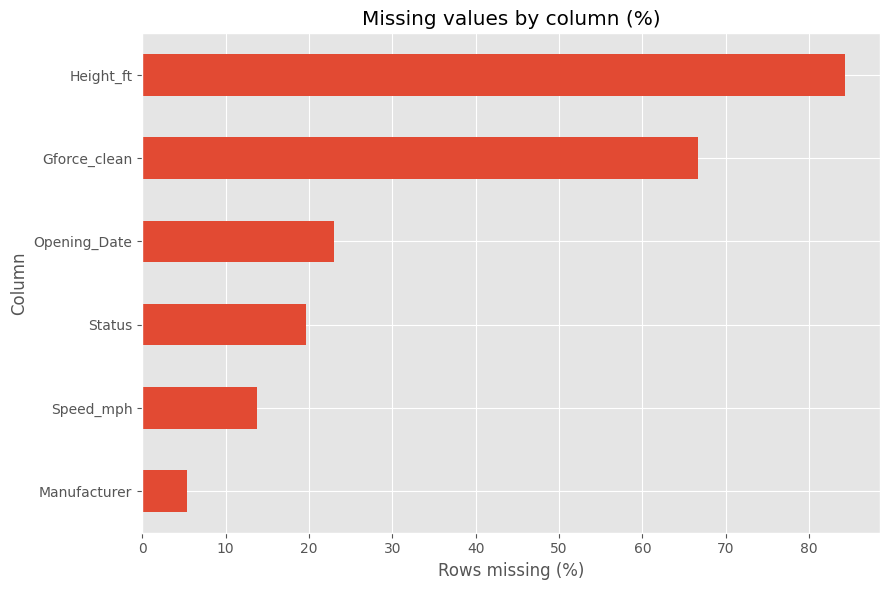

In [118]:
missing_audit = pd.DataFrame({
    "Missing_Count": df_new.isna().sum(),
    "Missing_Percent": (df_new.isna().mean() * 100).round(2),
}).sort_values("Missing_Percent", ascending=False)
display(missing_audit)

ax = missing_audit.loc[missing_audit["Missing_Count"] > 0, "Missing_Percent"].sort_values().plot(
    kind="barh", figsize=(9, 6), title="Missing values by column (%)"
)
ax.set_xlabel("Rows missing (%)")
ax.set_ylabel("Column")
plt.tight_layout()
plt.show()

# 7. FINDING DUPLICATES

In [119]:
df_new.loc[df_new.duplicated()]

,Coaster_Name,Location,Status,Manufacturer,Year_Introduced,Type_Main,Opening_Date,Speed_mph,Height_ft,Inversions_clean,Gforce_clean


In [120]:
df_new.loc[df_new.duplicated(subset = ['Coaster_Name'])]

,Coaster_Name,Location,Status,Manufacturer,Year_Introduced,Type_Main,Opening_Date,Speed_mph,Height_ft,Inversions_clean,Gforce_clean
43,Crystal Beach Cyclone,Crystal Beach Park,Removed,Traver Engineering,1927,Wood,1926-01-01,60.0,NaN,0,4.0
60,Derby Racer,Revere Beach,Removed,Fred W. Pearce,1937,Wood,1911-01-01,NaN,NaN,0,NaN
61,Blue Streak (Conneaut Lake),Conneaut Lake Park,Closed,NaN,1938,Wood,1938-05-23,50.0,NaN,0,NaN
167,Big Thunder Mountain Railroad,Other,NaN,Arrow Development (California and Florida)Dyna...,1980,Steel,NaT,35.0,NaN,0,NaN
237,Thunder Run (Canada's Wonderland),Canada's Wonderland,Operating,Mack Rides,1986,Steel,1981-05-23,39.8,32.8,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
1063,Lil' Devil Coaster,Six Flags Great Adventure,Operating,Zamperla,2021,Steel,1999-01-01,NaN,NaN,0,NaN
1064,Little Dipper (Conneaut Lake Park),Conneaut Lake Park,Operating,Allan Herschell Company,2021,Steel,1950-01-01,NaN,NaN,0,NaN
1080,Iron Gwazi,Busch Gardens Tampa Bay,Under construction,Rocky Mountain Construction,2022,Steel,NaT,76.0,NaN,2,NaN
1082,American Dreier Looping,Other,NaN,Anton Schwarzkopf,2022,Steel,NaT,53.0,NaN,3,4.7


In [121]:
df_new.query('Coaster_Name=="Crystal Beach Cyclone"')

,Coaster_Name,Location,Status,Manufacturer,Year_Introduced,Type_Main,Opening_Date,Speed_mph,Height_ft,Inversions_clean,Gforce_clean
39,Crystal Beach Cyclone,Crystal Beach Park,Removed,Traver Engineering,1926,Wood,1926-01-01,60.0,NaN,0,4.0
43,Crystal Beach Cyclone,Crystal Beach Park,Removed,Traver Engineering,1927,Wood,1926-01-01,60.0,NaN,0,4.0


# 8. WORKING AROUND DUPLICATES
A repeated coaster name alone is not enough evidence to delete a row. For example,
Crystal Beach Cyclone appears twice with different Year_Introduced values (1926 and 1927)
but the same Opening_Date. This could be a true duplicate or inconsistent historical
metadata; the dataset alone cannot confirm which.

To handle this, I treat (Coaster_Name, Location, Opening_Date) as the identifying key
and drop rows that repeat the same combination, keeping the first occurrence.

In [122]:
df_new = df_new.loc[~df_new.duplicated(subset=['Coaster_Name','Location','Opening_Date'])].reset_index(drop=True)

In [123]:
df_new.shape


(990, 11)

# 9. UNIVARIATE ANALYSIS
The first chart shows the ten most frequently represented introduction years in the cleaned dataset. This is a count of records by year.The histogram shows the distribution of recorded speeds.

Text(0, 0.5, 'Count')

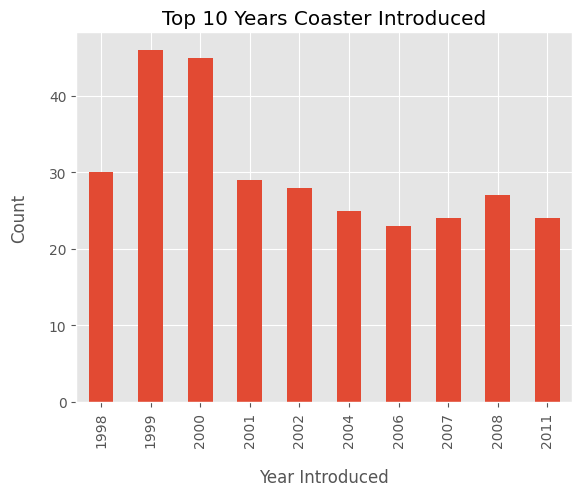

In [124]:
ax = df_new['Year_Introduced'].value_counts().head(10).sort_index() \
.plot(kind='bar',title = 'Top 10 Years Coaster Introduced')

ax.set_xlabel('Year Introduced', labelpad = 15)
ax.set_ylabel('Count', labelpad = 15)

Text(0, 0.5, 'Count')

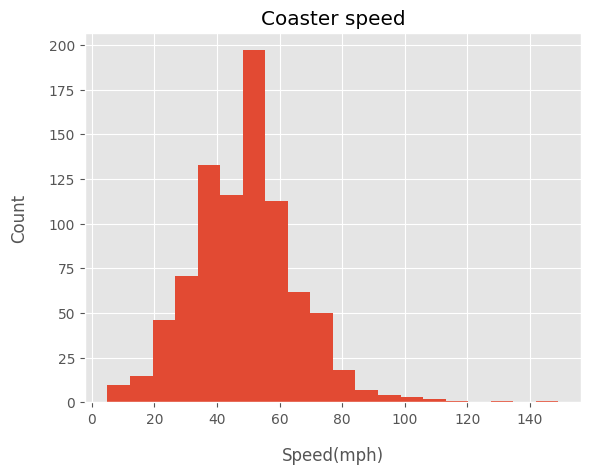

In [125]:
ax = df_new['Speed_mph'].plot(kind = 'hist', bins = 20, title = 'Coaster speed')
ax.set_xlabel('Speed(mph)', labelpad = 15)
ax.set_ylabel('Count', labelpad = 15)

# 10. FEATURES RELATIONSHIP

**Relationship between Speed and height** :  
The scatter plot uses only records with both speed and height available

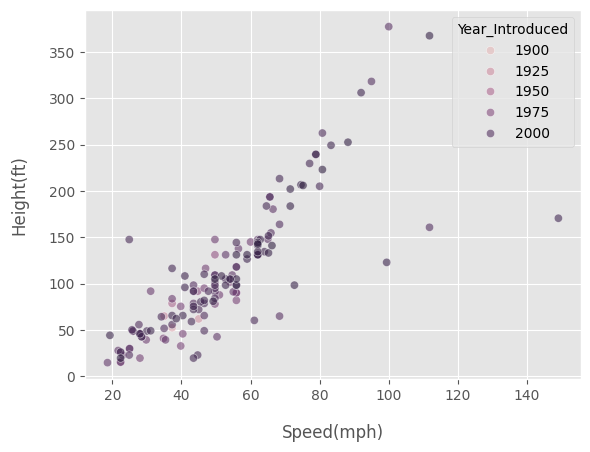

In [126]:
ax = sns.scatterplot(
    x = 'Speed_mph',
    y = 'Height_ft',
    alpha=0.6,
    hue = 'Year_Introduced',
    data = df_new
)
ax.set_xlabel('Speed(mph)', labelpad = 15)
ax.set_ylabel('Height(ft)', labelpad = 15)
plt.show()

**Material type across frequently represented years**

In [127]:
top_10_years = df_new['Year_Introduced'] \
.value_counts().head(10).index

top_years = df_new[df_new['Year_Introduced']\
.isin(top_10_years)
]
material_year = pd.crosstab(
    top_years['Year_Introduced'],
    top_years['Type_Main']
)
material_year

dominant_material = pd.DataFrame({
    'Material': material_year.idxmax(axis=1),
    'Count': material_year.max(axis=1)
})
dominant_material

,Material,Count
Year_Introduced,,
1998,Steel,23
1999,Steel,37
2000,Steel,35
2001,Steel,22
2002,Steel,26
2004,Steel,23
2006,Steel,17
2007,Steel,20
2008,Steel,22


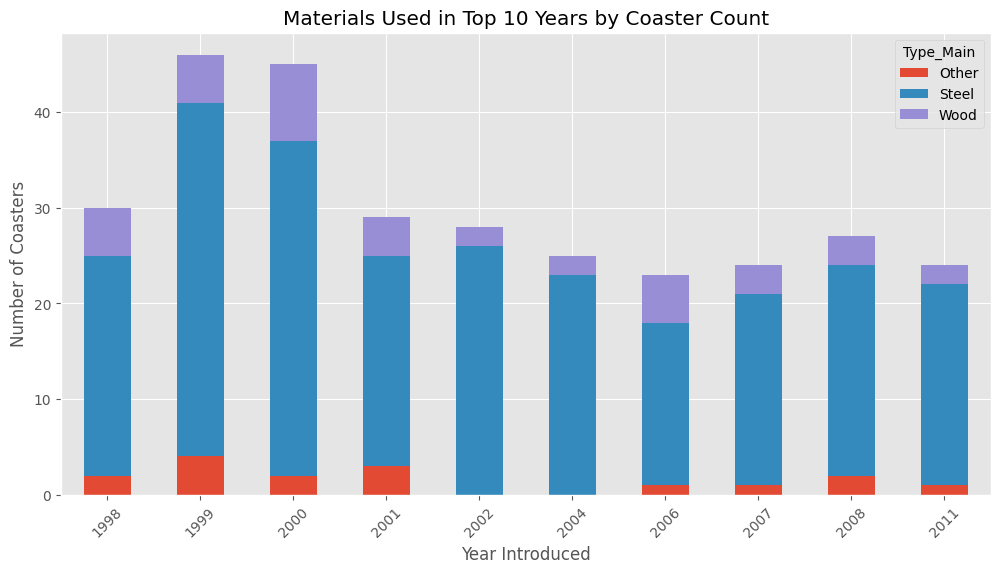

In [128]:
material_year.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6)
)

plt.title('Materials Used in Top 10 Years by Coaster Count')
plt.xlabel('Year Introduced')
plt.ylabel('Number of Coasters')
plt.xticks(rotation=45)
plt.show()

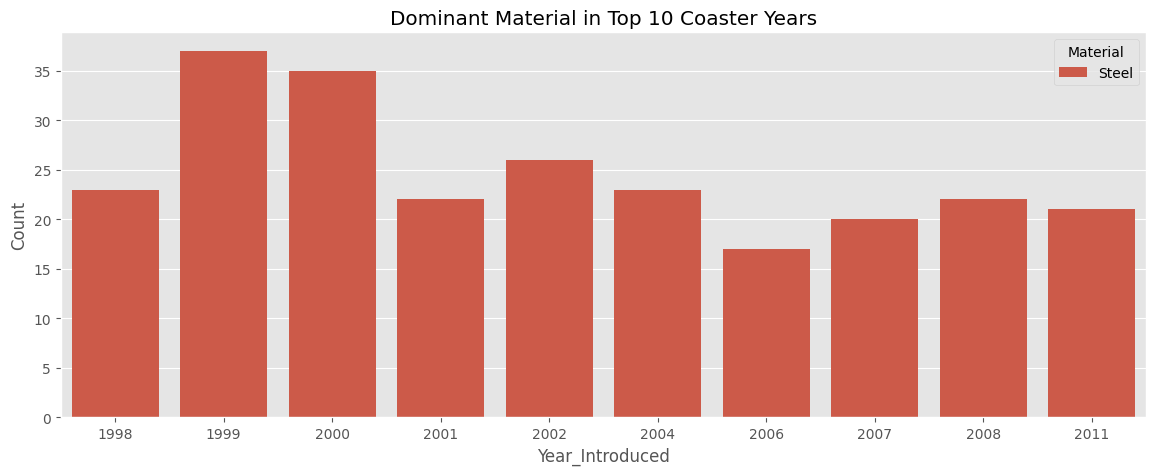

In [129]:
plt.figure(figsize=(14,5))
sns.barplot(
    data=dominant_material.reset_index(),
    hue='Material',
    x='Year_Introduced',
    y='Count'
)

plt.title('Dominant Material in Top 10 Coaster Years')
plt.show()

# 11. CORRELATION ANALYSIS: SPEED, HEIGHT AND G-FORCE
The correlation matrix uses complete-case rows: a row is included only if speed, height, and G-force are all present.

In [142]:
df.shape

(1087, 56)

In [130]:
df_corr = df_new[['Speed_mph', 'Height_ft','Gforce_clean']].dropna().corr()
df_corr

,Speed_mph,Height_ft,Gforce_clean
Speed_mph,1.000000,0.733999,0.607383
Height_ft,0.733999,1.000000,0.466482
Gforce_clean,0.607383,0.466482,1.000000


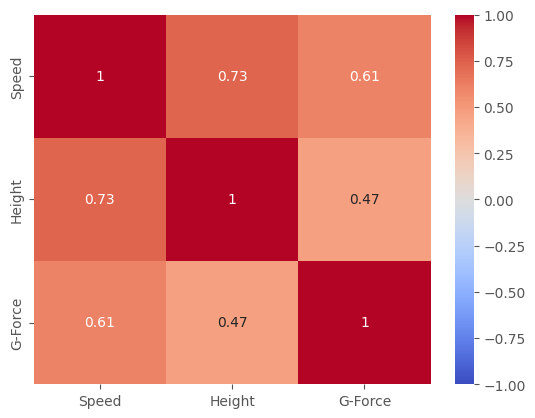

In [131]:
new_labels = ['Speed', 'Height', 'G-Force']

sns.heatmap(
    df_corr,
    annot=True,
    vmin=-1, vmax=1, cmap='coolwarm',
    xticklabels=new_labels,
    yticklabels=new_labels
)

plt.show()

# 12. AVERAGE SPEED BY LOCATION  

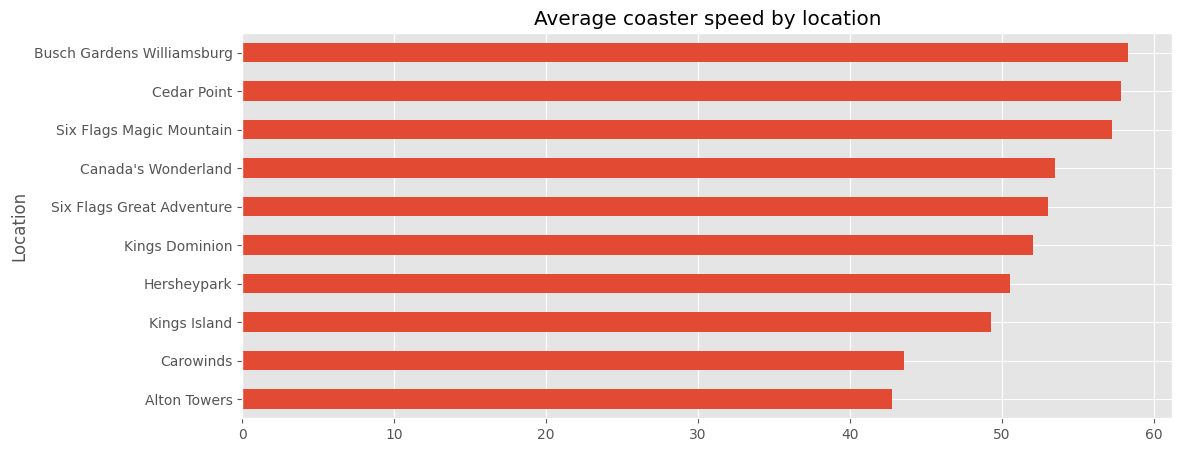

In [132]:
df_new.query('Location != "Other"')\
    .groupby('Location')['Speed_mph']\
    .agg(['mean','count'])\
    .query('count>=10')\
    .sort_values('mean')['mean']\
    .plot(kind='barh', figsize=(12,5), title='Average coaster speed by location')
plt.show()

Only locations with at least 10 speed records are shown (10 locations qualify), and
the "Other" category is excluded. Average speeds range from 42.8 mph at Alton Towers
(12 records) to 58.3 mph at Busch Gardens Williamsburg (11 records). Busch Gardens
Williamsburg, Cedar Point (57.8) and Six Flags Magic Mountain (57.2) are within about
1 mph of each other, so they are best read as a top group, not a strict ranking.

# 13. COASTER STATUS
The raw Status column had 15 labels, several of which differ only in wording or case
(e.g. "Temporarily Closed" vs "Temporarily closed"). I grouped them into four categories:
Operating, Closed permanently, Temporarily closed and Not yet open.
146 of the 990 coasters (14.7%) have no recorded status and are excluded. A further 25 are
not yet open and are also excluded. Of the remaining 819 coasters,
* Operating: 646 of 819, which is 78.9%
* Closed permanently: 166 of 819, which is 20.3%
* Temporarily closed: 7 of 819, which is 0.9%

In [133]:
df_new['Status'].value_counts(dropna=False)

Status
Operating                                                         646
NaN                                                               146
Removed                                                           133
Closed                                                             23
Under construction                                                 14
In Production                                                      11
Discontinued                                                        7
Chapter 7 bankruptcy; rides dismantled and sold; property sold      2
closed for maintenance as of july 30 no reopening date known        1
Not Currently Operating                                             1
SBNO December 2019                                                  1
Closed in 2021                                                      1
Temporarily Closed                                                  1
SBNO (Standing But Not Operating)                                   1
Temporarily c

In [134]:
status_map = {
    'Operating': 'Operating',
    'Removed': 'Closed permanently',
    'Closed': 'Closed permanently',
    'Discontinued': 'Closed permanently',
    'Closed in 2021': 'Closed permanently',
    'Chapter 7 bankruptcy; rides dismantled and sold; property sold': 'Closed permanently',
    'Temporarily Closed': 'Temporarily closed',
    'Temporarily closed': 'Temporarily closed',
    'Not Currently Operating': 'Temporarily closed',
    'Under Maintenance': 'Temporarily closed',
    'closed for maintenance as of july 30 no reopening date known': 'Temporarily closed',
    'SBNO December 2019': 'Temporarily closed',
    'SBNO (Standing But Not Operating)': 'Temporarily closed',
    'Under construction': 'Not yet open',
    'In Production': 'Not yet open',
}

df_new['Status_Group'] = df_new['Status'].map(status_map)

df_new['Status_Group'].isna().sum()       # should be 0; if not, a label is unmapped
df_new['Status_Group'].value_counts()

Status_Group
Operating             646
Closed permanently    166
Not yet open           25
Temporarily closed      7
Name: count, dtype: int64

In [135]:
active = df_new[df_new['Status_Group'].notna() & (df_new['Status_Group'] != 'Not yet open')]

type_counts = active['Type_Main'].value_counts()
keep = type_counts[type_counts >= 10].index

status_by_type = (
    pd.crosstab(active['Type_Main'], active['Status_Group'], normalize='index')
    .loc[keep]
    .round(2)
)
status_by_type

Status_Group,Closed permanently,Operating,Temporarily closed
Type_Main,,,
Steel,0.16,0.83,0.01
Wood,0.27,0.72,0.01
Other,0.52,0.48,0.00


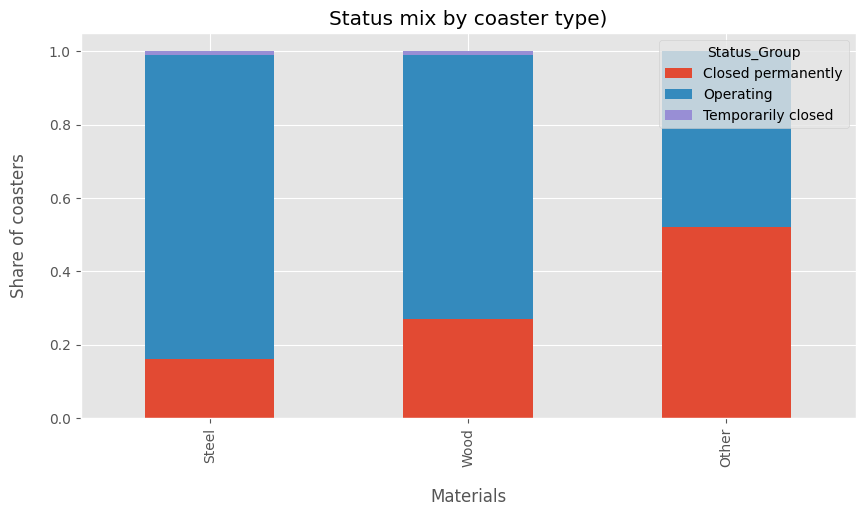

In [136]:
status_by_type.plot(kind='bar', stacked=True, figsize=(10, 5),
                    title='Status mix by coaster type)')
plt.ylabel('Share of coasters', labelpad=15)
plt.xlabel('Materials',labelpad=15)
plt.show()

Closure rates differ by type: 52% of "Other" coasters (48 coasters) are closed
permanently, compared with 27% of wooden (181) and 16% of steel (590) coasters.
"Other" is the smallest group, so its percentage is the least stable.

# 14. MANUFACTURER
Which manufacturers dominate the dataset, and how do their coasters compare? Only
manufacturers with at least 10 coasters are included. "Arrow Development" and "Arrow
Dynamics" were merged into one name because they are the same company.

In [137]:
df_new['Manufacturer'] = df_new['Manufacturer'].replace('Arrow Development', 'Arrow Dynamics')

In [138]:
mfr = (
    df_new.groupby('Manufacturer')
    .agg(
        Coasters=('Coaster_Name', 'count'),
        Speed_Records=('Speed_mph', 'count'),
        Avg_Speed=('Speed_mph', 'mean'),
        Height_Records=('Height_ft', 'count'),
        Max_Height=('Height_ft', 'max'),
        Avg_Inversions=('Inversions_clean', 'mean'),
    )
    .query('Coasters >= 10')
    .sort_values('Coasters', ascending=False)
    .round(1)
)
mfr

,Coasters,Speed_Records,Avg_Speed,Height_Records,Max_Height,Avg_Inversions
Manufacturer,,,,,,
Vekoma,122,115,43.5,27,193.6,2.3
Bolliger & Mabillard,104,104,61.7,18,306.1,3.6
Intamin,84,79,62.1,21,377.3,1.1
Arrow Dynamics,72,70,47.1,4,131.2,1.5
Mack Rides,53,49,39.7,23,202.1,0.6
Anton Schwarzkopf,45,31,44.2,2,145.0,0.9
Gerstlauer,45,45,46.6,16,239.5,2.3
Philadelphia Toboggan Coasters,32,28,41.5,1,65.0,0.0
Custom Coasters International,30,28,51.4,0,NaN,0.0


Vekoma has the most coasters (122), followed by Bolliger & Mabillard (104), Intamin (84)
and Arrow Dynamics (72).
Having the most coasters does not mean the fastest: Vekoma
averages 43.5 mph, compared with 61.7 mph for Bolliger & Mabillard and 62.1 mph for
Intamin. Bolliger & Mabillard also has the highest average inversions (3.6), while
Intamin's is 1.1.

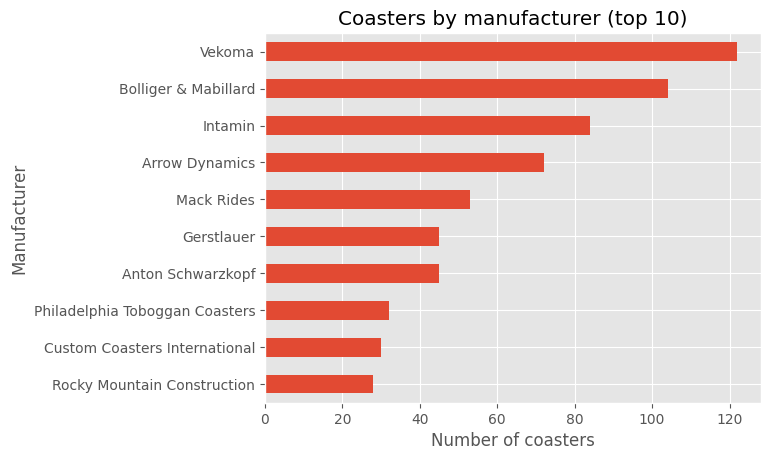

In [139]:
mfr['Coasters'].head(10).sort_values().plot(kind='barh', title='Coasters by manufacturer (top 10)')
plt.xlabel('Number of coasters')
plt.show()

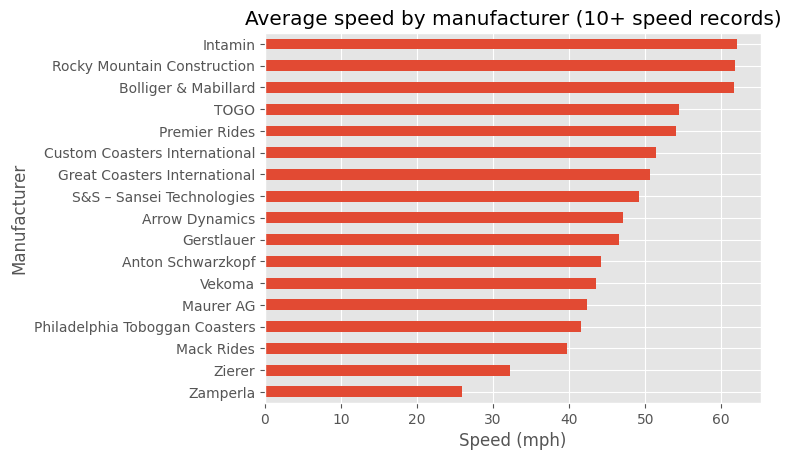

In [140]:
mfr[mfr['Speed_Records'] >= 10]['Avg_Speed'].sort_values().plot(
    kind='barh', title='Average speed by manufacturer (10+ speed records)')
plt.xlabel('Speed (mph)')
plt.show()

In [145]:
df_new.shape

(990, 12)

In [146]:
df_new[['Speed_mph', 'Height_ft', 'Gforce_clean']].dropna().shape[0]

67

In [147]:
removed = df.loc[df.duplicated(subset=['coaster_name', 'Location', 'opening_date_clean'])]
len(removed), removed['opening_date_clean'].isna().sum()

(97, np.int64(67))

In [148]:
df_new[['Speed_mph', 'Height_ft', 'Gforce_clean']].dropna().shape[0]


67

In [149]:
df_new.columns.tolist()

['Coaster_Name',
 'Location',
 'Status',
 'Manufacturer',
 'Year_Introduced',
 'Type_Main',
 'Opening_Date',
 'Speed_mph',
 'Height_ft',
 'Inversions_clean',
 'Gforce_clean',
 'Status_Group']

# 15. KEY FINDINGS
1. **Status:** Of the 819 coasters with a recorded status that are open or have closed,
   78.9% are operating and 20.3% are closed permanently. Closure is most common among
   "Other" types (52%), then wooden (27%) and steel (16%).
2. **Manufacturers:** Vekoma has the most coasters (122), but Bolliger & Mabillard
   (61.7 mph) and Intamin (62.1 mph) average much higher speeds than Vekoma (43.5 mph).
   Bolliger & Mabillard has the highest average inversions (3.6).
3. **Speed, height and G-force:** Speed and height have a strong positive correlation
   (0.73), speed and G-force a moderate-to-strong one (0.61), and height and G-force a
   moderate one (0.47). These use only the 67 coasters that have all three values. They
   describe association, not cause: taller coasters tend to be faster, but this analysis
   cannot say why.
4. **Location:** Among locations with at least 10 speed records, Busch Gardens
   Williamsburg, Cedar Point and Six Flags Magic Mountain have the highest average speeds
   (about 57-58 mph). Alton Towers has the lowest (42.8 mph).

# 16. LIMITATIONS
- The dataset was already cleaned by its original author; my work starts from that file.
- 14.7% of coasters (146 of 990) have no recorded Status, so status shares describe only
  coasters that have one.
- Height is missing for most coasters (for example, Vekoma has 27 heights for 122
  coasters), so manufacturer comparisons on height are not reliable.
- The speed, height and G-force correlations use only 67 of 990 coasters, because height
  and G-force are missing for most. They may not represent the full dataset.
- Duplicates were removed using (Coaster_Name, Location, Opening_Date). 97 of 1,087 rows
  (8.9%) were removed. pandas treats missing values as equal, so 67 of the 97 removed
  rows had no Opening_Date and were matched on name and location alone. Some of these may
  be distinct coasters rather than true duplicates; only 30 removals used a complete key.
- Status grouping (Closed permanently vs Temporarily closed) is based on the label text
  and is a judgement call.
- Location averages cover only 10 locations with at least 10 speed records each.
- Correlations and group comparisons are descriptive and do not show causation.